# 02 — Inflow reconstruction

**What this notebook shows.** The weekly energy inflow to the aggregated Swedish hydro reservoir, reconstructed from the reservoir's energy balance, and the inflow scenarios used by the water value model of notebook 04: one equally likely scenario per historical ISO year, with 52 weekly stages each. It shows how negative values and the weeks without production data are handled, the seasonal pattern, and which years were dry and wet.

All numbers are computed by `watervalues.inflow` from `data/processed/weekly_se.csv`. This is the same code that `uv run watervalues inflow` runs to write the weekly inflow, the scenario matrix and the report to `outputs/`.

In [1]:
from watervalues import plots
from watervalues.config import PROJECT_ROOT, load_config
from watervalues.data.build import load_weekly
from watervalues.inflow import build_inflow, dry_and_wet

cfg = load_config()
result = build_inflow(cfg, load_weekly(PROJECT_ROOT / cfg.data.weekly_csv))
report = "\n".join(result.report)
plots.use_style()
print(report[: report.index("Negative")].strip())

Inflow I = storage_end - storage + hydro [GWh] (energy balance; spill not observed, taken as 0)
Scenario matrix: J = 11 ISO years (2015-2025) x 52 stages [GWh per 168-h stage], probability 1/J each


## Method

With $S_w$ the storage at the start of week $w$, $P_w$ the hydro production and $Sp_w$ the spill, the energy balance of the reservoir gives the inflow

$$I_w = (S_{w+1} - S_w) + P_w + Sp_w \quad [\text{GWh}].$$

- **Spill is not observed** and is taken as zero, so the inflow of very wet weeks, when reservoirs spill, is underestimated.
- $P_w$ is all hydro production (ENTSO-E reports all Swedish hydro as reservoir hydro), so $I_w$ is the **total** energy inflow, regulated and unregulated.
- The balance is computed on the weekly rows as published. A folded week 52 (week 53 merged into it, 336 hours) is rescaled to a standard 168-hour stage only afterwards, because its storage change spans both weeks.
- The reservoir convention matters here. The value published for week $w$ is the storage at the end of week $w$ (notebook 01). A one-week shift would pair the production of one week with the storage change of another.

## Negative values and weeks without production data

In [2]:
print(report[report.index("Negative") : report.index("Annual totals")].strip())

Negative weekly balances clipped to 0 (noise band -150 GWh): 1
  2016-W50: -50.0 GWh
Weeks without hydro production, given the mean stage inflow of the same ISO week in the other years: 2
  2015-W01: 641.0 GWh
  2015-W50: 610.5 GWh


One week has a small negative balance. It lies well inside the storage-reporting noise band (`inflow.negative_noise_gwh` in `config/base.yaml`), which is about twice the winter RMSE of this inflow against Energiföretagen's published inflow. A negative is physically impossible, so it is clipped to zero and listed. A negative beyond the band would stop the pipeline, because it would point to a misaligned reservoir series or bad production data rather than noise.

Two weeks of 2015 have no hydro production on ENTSO-E (`data/known_gaps.yaml`): the storage is known, but without production the balance cannot be closed. Their inflow is set to the mean of the same ISO week in the other years. That adds no information about 2015, but it keeps the rest of that year in the scenario set, and 2015 is one of only eleven hydrological years and a wet one. Only the scenario matrix is filled; the weekly dataset keeps its gaps.

## Seasonal pattern

Climatology of the stage inflow [GWh per stage]
  highest mean: week 20 (3539 GWh; over the years 1176 to 5818)
  lowest mean: week 10 (488 GWh; over the years 310 to 758)
  weeks with a mean above the average stage (1301 GWh): 17-33, 39-41, 62% of the mean annual inflow


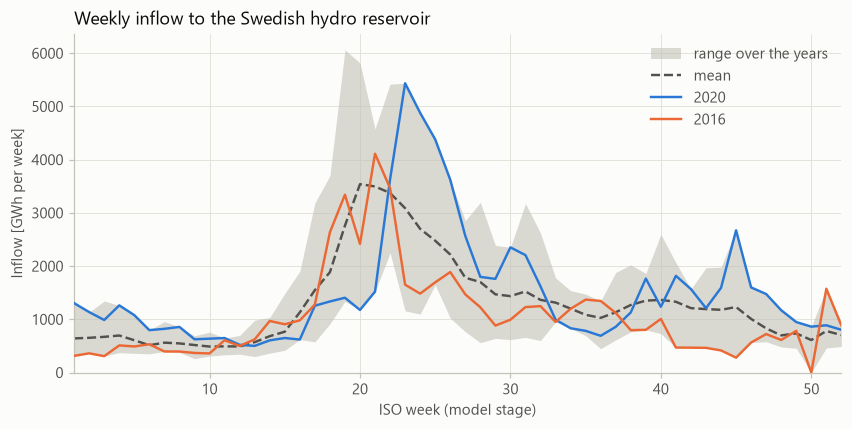

In [3]:
driest, wettest = dry_and_wet(result.annual)
ax = plots.inflow_climatology(result.scenarios, highlight=[wettest, driest])
ax.set_title("Weekly inflow to the Swedish hydro reservoir")
print(report[report.index("Climatology") :].strip())

Inflow is small and steady through the winter, when precipitation is stored as snow. The snowmelt flood in May and June brings a large share of the year's water within a few weeks, and autumn rain adds a second, smaller and more variable season. The spread between years is widest during the flood, whose timing and size both vary. This is what makes the problem stochastic: the reservoir must be drawn down through the winter before anyone knows how large the next flood will be.

The two highlighted years differ in more than their totals. In the wettest year the flood came late but was large, and the autumn was wet as well. In the driest year the flood came early and ended quickly, and the rest of the year stayed below the mean. The drop to zero near the end of the driest year is the clipped week.

## Annual totals: dry and wet years

Totals in TWh per ISO year. `iso` sums the actual hours of the ISO year, which can be compared with published statistics. `model` sums the 52 standard stages that the water value model uses, so years of 52 and 53 ISO weeks compare on equal length. Years are ranked by the model-year inflow (`wet_rank` 1 is the wettest).

In [4]:
result.annual.round(1)

,inflow_iso_twh,inflow_model_twh,hydro_iso_twh,hydro_model_twh,clipped_weeks,imputed_weeks,wet_rank
iso_year,,,,,,,
2015,76.1,75.5,NaN,NaN,0,2,2
2016,55.4,55.4,61.3,61.3,1,0,11
2017,69.2,69.2,64.9,64.9,0,0,4
2018,58.4,58.4,61.9,61.9,0,0,10
2019,67.2,67.2,65.4,65.4,0,0,7
2020,79.7,78.9,74.2,72.5,0,0,1
2021,68.8,68.8,73.8,73.8,0,0,5
2022,67.9,67.9,69.4,69.4,0,0,6
2023,65.4,65.4,65.8,65.8,0,0,8


driest 2016 (55.4 TWh), wettest 2020 (78.9 TWh)
  inflow per model year, all 11 years: mean 67.6 TWh, std 6.8 TWh (coefficient of variation 10.0%)
  the 10 years with complete production data, per model year:
    inflow mean 66.8 TWh, std 6.6 TWh (coefficient of variation 9.9%)
    hydro production mean 66.8 TWh, std 4.2 TWh (coefficient of variation 6.2%)


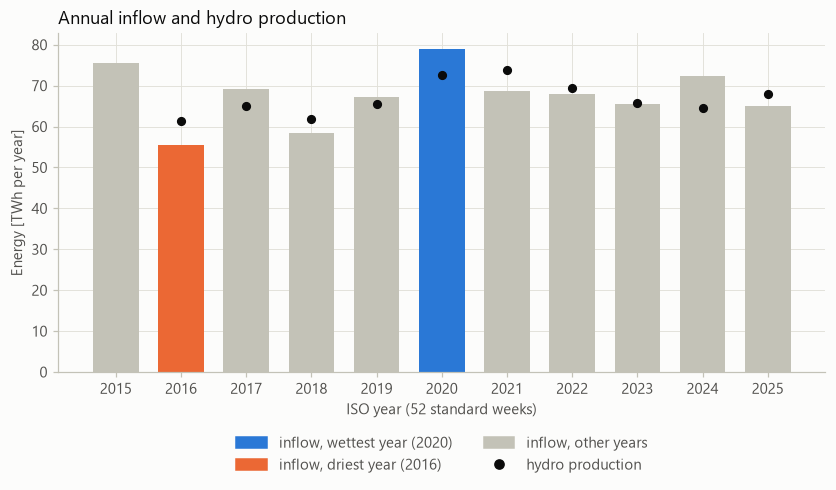

In [5]:
ax = plots.annual_inflow(result.annual, dry=driest, wet=wettest)
ax.set_title("Annual inflow and hydro production")
print(report[report.index("  driest") : report.index("Climatology")].strip())

Annual inflow varies much more than production: the reservoir carries water from one year to the next. In dry years production exceeds inflow and the reservoir is drawn down; after the wettest year, production stays above inflow while the stored surplus is used. The driest year in the record is not 2018, the year remembered for its drought summer. The annual total counts the whole year, and 2018 ranks second-driest. Over the years with complete production data, mean inflow and mean production are close: the reservoir holds only a fraction of one year's inflow, so over many years what flows in must be produced.

2015 has no production marker and no production total in the table. Two of its weeks have no production data, so its annual production is unknown. Their inflow is imputed; their production is not.

## Cross-check against Energiföretagen's published inflow

Energiföretagen publishes a weekly inflow estimate in its weekly statistics. `watervalues validate` compares it, for 2019–2025, with the inflow that the same balance gives under each reservoir convention (bias = this balance minus the published inflow):

In [6]:
validation = (PROJECT_ROOT / cfg.data.energiforetagen.report).read_text(encoding="utf-8")
print(validation[validation.index("3) Workbook") : validation.index("4) RMSE")].strip())

3) Workbook inflow vs inflow implied by the ENTSO-E labels [GWh/week]
                             corr  rmse_gwh  bias_gwh    n
convention    window                                      
start_of_week all weeks     0.786   663.009   -40.528  361
              winter weeks  0.205   369.767    26.796   91
end_of_week   all weeks     0.989   163.284   -41.953  360
              winter weeks  0.941    76.138    10.170   91
weekly_mean   all weeks     0.931   375.308   -41.415  360
              winter weeks  0.618   192.015    18.483   91


With the end-of-week convention, the balance tracks the published inflow closely. Its winter error sets the noise band used for negatives above. The bias is negative: on average this inflow lies slightly below the published one. Possible reasons are the spill that the balance ignores and the slightly different storage scales of the two sources (see `data/README.md`). The bias is reported, not corrected.

## Limitations

- Spill is not observed, so inflow is underestimated in weeks when reservoirs spill, most likely at the peak of large floods.
- Storage-reporting noise enters every weekly value twice, through the storage at the start and at the end of the week. It cancels in sums over many weeks, so annual totals are much more reliable than single weeks.
- The build interpolated two weekly storage values (listed in `data/processed/build_report.txt`). The storage change over the two weeks around each is measured, but it is split evenly between them, so those weekly inflows are less reliable than the rest.
- A 52-stage year averages the folded week 52 of the two 53-week years, so their model year holds one week less inflow than their ISO year.
- Eleven years make a short record, and droughts or floods more extreme than these years are not in the scenario set.
- The inflow is a national aggregate: differences between the northern and southern zones and transmission limits are outside this model.

## The scenario matrix

In [7]:
print(f"{result.scenarios.shape[0]} years x {result.scenarios.shape[1]} stages")
result.scenarios.iloc[:, ::4].round(0)  # every fourth stage, GWh per 168-hour stage

11 years x 52 stages


iso_week,1,5,9,13,17,21,25,29,33,37,41,45,49
iso_year,,,,,,,,,,,,,
2015,641.0,580.0,589.0,520.0,1633.0,3112.0,2271.0,2391.0,1459.0,613.0,1204.0,1299.0,788.0
2016,313.0,490.0,367.0,623.0,1276.0,4111.0,1695.0,882.0,950.0,1120.0,469.0,279.0,783.0
2017,681.0,600.0,493.0,651.0,575.0,3798.0,2964.0,2243.0,1530.0,1881.0,1408.0,985.0,762.0
2018,676.0,517.0,261.0,299.0,2434.0,3190.0,1647.0,640.0,957.0,856.0,1117.0,967.0,764.0
2019,583.0,361.0,692.0,700.0,3185.0,3970.0,3006.0,1131.0,992.0,1401.0,833.0,582.0,881.0
2020,1303.0,1078.0,624.0,501.0,1255.0,1519.0,4381.0,1760.0,993.0,859.0,1817.0,2672.0,948.0
2021,757.0,460.0,668.0,984.0,887.0,3915.0,2114.0,1048.0,1504.0,814.0,2064.0,1263.0,560.0
2022,506.0,588.0,445.0,612.0,1597.0,4578.0,2680.0,1547.0,1716.0,980.0,1089.0,1517.0,485.0
2023,490.0,517.0,469.0,380.0,1450.0,3981.0,2595.0,1497.0,1779.0,1202.0,1306.0,778.0,455.0


This matrix (GWh per 168-hour stage) is the hydrological uncertainty of the water value model: in every stage, each historical year is an equally likely inflow outcome. `uv run watervalues inflow` writes it to `outputs/inflow_scenarios.csv`, next to the weekly inflow with the status of every week (`observed`, `clipped` or `imputed`) and this notebook's report.